In [10]:
BASE_DIR = Path(r'C:\Users\user\Desktop\hackaton\NASA-Space-Challange\wearable-model\wearable-device-dataset-1.0.1\wearable-device-dataset-from-induced-stress-and-structured-exercise-sessions-1.0.1')

In [19]:
# ==========================================
# 1. FUNKCJA WCZYTUJĄCA SYGNAŁY EMPATICA E4
# ==========================================

def load_signal(folder, filename, columns):

    raw = pd.read_csv(folder / filename, header=None)

    # Czas rozpoczęcia pomiaru
    start_time = pd.to_datetime(raw.iloc[0, 0], utc=True)

    # Częstotliwość próbkowania
    fs = float(raw.iloc[1, 0])

    # Wartości sygnału
    values = raw.iloc[2:, :len(columns)].apply(
        pd.to_numeric, errors="coerce"
    ).reset_index(drop=True)

    # Indeksy czasowe próbek
    timestamps = (
        start_time
        + pd.to_timedelta(np.arange(len(values)) / fs, unit="s")
    )

    values.index = timestamps
    values.columns = columns

    return values

In [20]:
# ==========================================
# 2. FUNKCJA WCZYTUJĄCA CAŁĄ SESJĘ
# ==========================================

def load_session(folder, session_name, label):

    # Wczytanie sygnałów
    acc = load_signal(folder, "ACC.csv", ["ACC_x", "ACC_y", "ACC_z"])
    bvp = load_signal(folder, "BVP.csv", ["BVP"])
    eda = load_signal(folder, "EDA.csv", ["EDA"])
    temp = load_signal(folder, "TEMP.csv", ["TEMP"])
    hr = load_signal(folder, "HR.csv", ["HR"])

    # Synchronizacja sygnałów do 1 Hz
    df = pd.concat(
        [
            acc.resample("1s").mean(),
            bvp.resample("1s").mean(),
            eda.resample("1s").mean(),
            temp.resample("1s").mean(),
            hr.resample("1s").mean()
        ],
        axis=1
    )

    # Wypadkowa przyspieszenia
    df["ACC_magnitude"] = np.sqrt(
        df["ACC_x"]**2 +
        df["ACC_y"]**2 +
        df["ACC_z"]**2
    )

    # Etykiety
    df["session"] = session_name
    df["label"] = label
    df["label_encoded"] = 0 if label == "AEROBIC" else 1

    return df

In [23]:
def load_tags(participant, session):
    folder = BASE_DIR / "Wearable_Dataset" / session / participant

    tags_file = folder / "tags.csv"
    hr_file = folder / "HR.csv"

    if not tags_file.exists() or not hr_file.exists():
        return None

    with open(hr_file, "r") as f:
        start_time = pd.to_datetime(f.readline().strip(), utc=True)

    tags = pd.read_csv(tags_file, header=None).iloc[:, 0]
    tags = pd.to_datetime(tags, utc=True)

    result = pd.DataFrame({"tag_time": tags})
    result["time_min"] = (
        result["tag_time"] - start_time
    ).dt.total_seconds() / 60

    return result

In [15]:
import pandas as pd
from pathlib import Path

files = []
for filename in ["Stress_Level_v1.csv", "Stress_Level_v2.csv"]:
    file = BASE_DIR / filename
    files.append(file)

    print("\n" + "=" * 50)
    print(filename)

    if file.exists():
        df = pd.read_csv(file)

        print("Wymiary:", df.shape)
        print("\nKolumny:")
        print(df.columns.tolist())

        print("\nPierwsze 10 wierszy:")
        print(df.head(10).to_string(index=False))

        print("\nTypy danych:")
        print(df.dtypes)
    else:
        print("Plik nie istnieje:", file)


Stress_Level_v1.csv
Wymiary: (18, 9)

Kolumny:
['Unnamed: 0', 'Baseline', 'Stroop', 'First Rest', 'TMCT', 'Second Rest', 'Real Opinion', 'Opposite Opinion', 'Subtract']

Pierwsze 10 wierszy:
Unnamed: 0  Baseline  Stroop  First Rest  TMCT  Second Rest  Real Opinion  Opposite Opinion  Subtract
       S01       3.0     4.5         4.0   4.0          5.5           6.0               7.0       7.0
       S02       2.0     4.0         2.0   2.0          2.0           4.0               5.0       4.0
       S03       3.0     3.0         3.0   4.0          3.0           3.0               3.0       3.0
       S04       3.0     3.0         2.0   3.0          1.0           1.0               1.0       1.0
       S05       1.0     2.0         1.0   4.0          1.0           2.0               2.0       3.0
       S06       2.0     3.0         2.0   5.0          3.0           3.0               3.0       5.0
       S07       5.0     6.0         6.0   8.0          7.0           8.0               9.0   

In [12]:
df.head()

,Unnamed: 0,Baseline,TMCT,First Rest,Real Opinion,Opposite Opinion,Second Rest,Subtract
0,f01,2.0,5.0,2.0,3.0,4.0,2.0,3.0
1,f02,3.0,5.0,1.0,2.0,3.0,2.0,3.0
2,f03,5.0,8.0,1.0,3.0,5.0,1.0,6.0
3,f04,2.0,4.0,3.0,3.0,4.0,1.0,4.0
4,f05,3.0,4.0,3.0,3.0,3.0,2.0,3.0


In [24]:
for participant in ["S01", "f01"]:
    folder = BASE_DIR / "Wearable_Dataset" / "STRESS" / participant

    print("\n" + "=" * 50)
    print("Uczestnik:", participant)

    if not folder.exists():
        print("Brak folderu")
        continue

    tags = load_tags(participant, "STRESS")

    if tags is None:
        print("Brak tags.csv lub HR.csv")
        continue

    print("Liczba tagów:", len(tags))
    print(tags.to_string(index=False))

    hr_file = folder / "HR.csv"
    with open(hr_file, "r") as f:
        start_time = pd.to_datetime(f.readline().strip(), utc=True)
        fs = float(f.readline().strip())

    hr = pd.read_csv(hr_file, header=None).iloc[2:, 0]
    duration_min = len(hr) / fs / 60

    print("\nCzas trwania sesji:", round(duration_min, 2), "min")


Uczestnik: S01
Liczba tagów: 13
                 tag_time  time_min
2013-02-20 18:01:30+00:00  6.016667
2013-02-20 18:05:37+00:00 10.133333
2013-02-20 18:08:32+00:00 13.050000
2013-02-20 18:10:17+00:00 14.800000
2013-02-20 18:17:37+00:00 22.133333
2013-02-20 18:19:42+00:00 24.216667
2013-02-20 18:24:49+00:00 29.333333
2013-02-20 18:25:17+00:00 29.800000
2013-02-20 18:25:55+00:00 30.433333
2013-02-20 18:26:32+00:00 31.050000
2013-02-20 18:27:14+00:00 31.750000
2013-02-20 18:27:46+00:00 32.283333
2013-02-20 18:28:01+00:00 32.533333

Czas trwania sesji: 36.92 min

Uczestnik: f01
Liczba tagów: 9
                 tag_time  time_min
2013-06-12 16:23:45+00:00  4.616667
2013-06-12 16:25:46+00:00  6.633333
2013-06-12 16:33:18+00:00 14.166667
2013-06-12 16:47:32+00:00 28.400000
2013-06-12 16:48:09+00:00 29.016667
2013-06-12 16:48:30+00:00 29.366667
2013-06-12 16:49:02+00:00 29.900000
2013-06-12 17:08:31+00:00 49.383333
2013-06-12 17:08:57+00:00 49.816667

Czas trwania sesji: 54.05 min


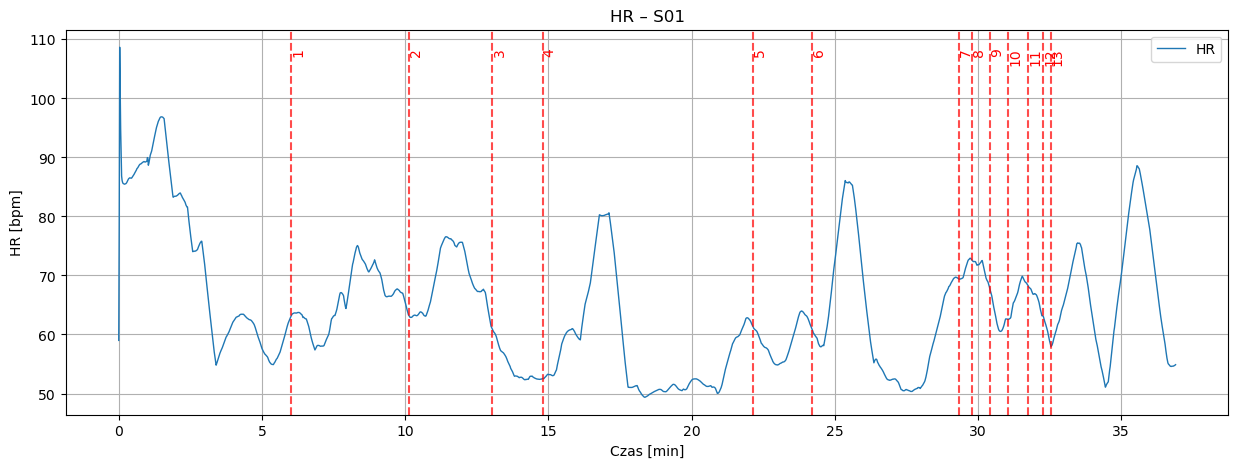

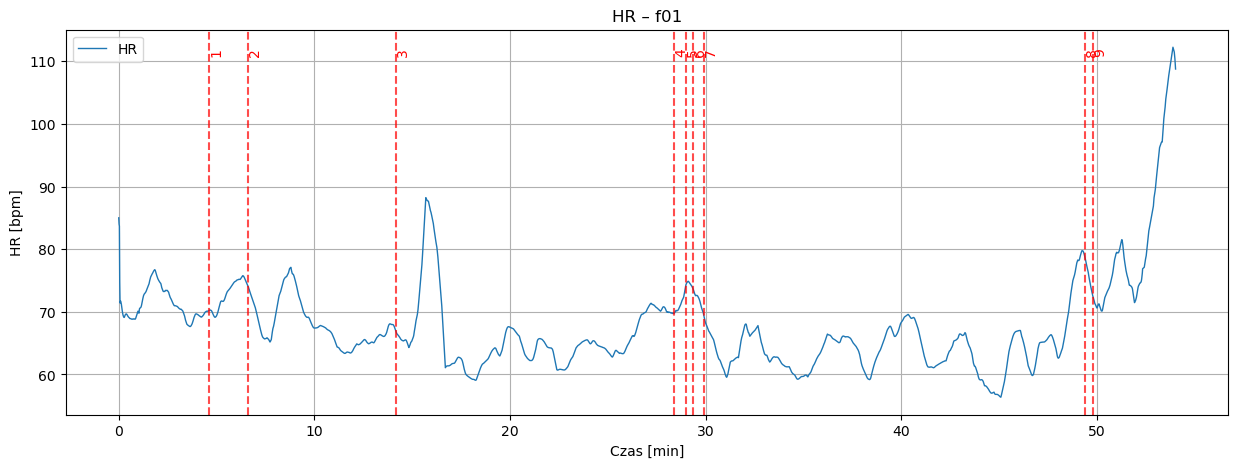

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

for participant in ["S01", "f01"]:

    folder = BASE_DIR / "Wearable_Dataset" / "STRESS" / participant

    hr_file = folder / "HR.csv"

    with open(hr_file, "r") as f:
        start_time = pd.to_datetime(f.readline().strip(), utc=True)
        fs = float(f.readline().strip())

    hr = pd.read_csv(hr_file, header=None).iloc[2:, 0]
    hr = pd.to_numeric(hr).reset_index(drop=True)

    time_min = np.arange(len(hr)) / fs / 60

    tags = load_tags(participant, "STRESS")

    plt.figure(figsize=(15, 5))
    plt.plot(time_min, hr, linewidth=1, label="HR")

    for i, tag in enumerate(tags["time_min"]):
        plt.axvline(tag, color="red", linestyle="--", alpha=0.7)
        plt.text(tag, hr.max(), str(i + 1), color="red",
                 rotation=90, va="top")

    plt.title(f"HR – {participant}")
    plt.xlabel("Czas [min]")
    plt.ylabel("HR [bpm]")
    plt.grid()
    plt.legend()
    plt.show()